Homework 6, problem 1, part b and c

In [1]:
# libraries and parameters
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

rho = 0.5
p_H = 0.5
tau = 5.0

In [2]:
def R_analytic(T):
    food = p_H * (1 - np.exp(-rho * T))
    time = p_H * (1 - np.exp(-rho * T)) / rho + (1 - p_H) * T + tau
    return food / time

def lambda_tilde(T):
    num = rho * p_H * np.exp(-rho * T)
    den = p_H * np.exp(-rho * T) + (1 - p_H)
    return num / den

R_known = p_H / (p_H / rho + tau)

In [3]:
# part b, find T* and R* numerically
T_star = brentq(lambda T: R_analytic(T) - lambda_tilde(T), 0.1, 20.0)
R_star = R_analytic(T_star)
print(T_star, R_star)

4.181434810310969 0.05500115972326259


In [4]:
# part i, Monte Carlo Simulation of 4e5 patch visits
np.random.seed(42)
N = 400_000

print(f"{'T':<10} | {'Simulated R(T)':<16} | {'Analytical R(T)':<16} | {'Abs Error':<10}")
print("-" * 60)

for label, T_val in [("2", 2.0), ("T*", T_star), ("10", 10.0)]:
    is_high = np.random.rand(N) < p_H
    find_times = np.random.exponential(scale=1/rho, size=N)
    
    # food is 1 only if patch is high AND food is found before T_val
    food_collected = is_high & (find_times <= T_val)
    
    # time in patch is min(find_time, T_val) for high patches, and T_val for low patches
    residence_time = np.where(is_high, np.minimum(find_times, T_val), T_val)
    total_time = residence_time + tau
    
    sim_R = np.sum(food_collected) / np.sum(total_time)
    ana_R = R_analytic(T_val)
    print(f"{label:<10} | {sim_R:<16.6f} | {ana_R:<16.6f} | {abs(sim_R - ana_R):<10.6f}")

T          | Simulated R(T)   | Analytical R(T)  | Abs Error 
------------------------------------------------------------
2          | 0.047655         | 0.047656         | 0.000001  
T*         | 0.054991         | 0.055001         | 0.000010  
10         | 0.045239         | 0.045176         | 0.000063  


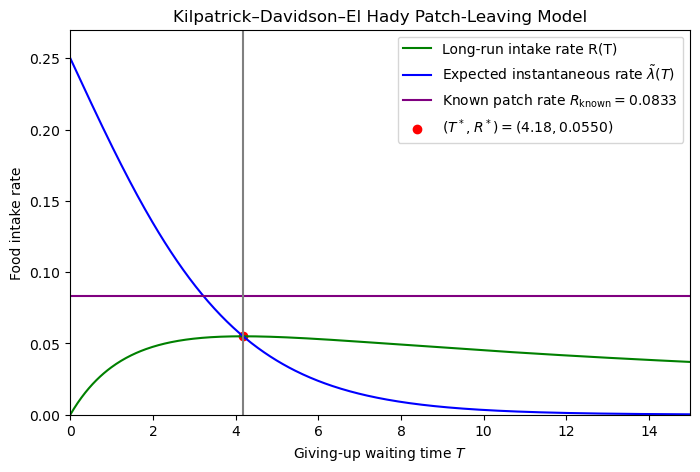

In [5]:
# part ii
T_grid = np.linspace(0, 15, 500)
plt.figure(figsize=(8, 5))

plt.plot(T_grid, R_analytic(T_grid), label = 'Long-run intake rate R(T)', color = 'green')
plt.plot(T_grid, lambda_tilde(T_grid), label = r'Expected instantaneous rate $\tilde{\lambda}(T)$', color = 'blue')
plt.axhline(R_known, label=rf'Known patch rate $R_{{\mathrm{{known}}}} = {R_known:.4f}$', color = 'purple')

plt.scatter([T_star], [R_star], label = rf'$(T^*, R^*) = ({T_star:.2f}, {R_star:.4f})$', color='red')
plt.axvline(T_star, color='gray')

plt.title('Kilpatrick–Davidson–El Hady Patch-Leaving Model')
plt.xlabel('Giving-up waiting time $T$')
plt.ylabel('Food intake rate')
plt.xlim(0, 15)
plt.ylim(0, 0.27)
plt.legend()
plt.show()